In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

METEO = Path("../data/raw/meteo")

In [2]:
ber = pd.read_csv(METEO / "ogd-smn_ber_d_historical.csv", sep=";")
print(ber.shape)
ber.iloc[:3, :6]      # first 3 rows, first 6 columns

(59170, 41)


,station_abbr,reference_timestamp,tre200d0,tre200dx,tre200dn,tre005d0
0,BER,01.01.1864 00:00,-1.3,0.7,-5.7,NaN
1,BER,02.01.1864 00:00,-10.3,-5.7,-12.8,NaN
2,BER,03.01.1864 00:00,-12.2,-10.2,-13.6,NaN


In [3]:
ber = ber[["station_abbr", "reference_timestamp", "tre200d0"]].copy()

# dates are text "dd.mm.yyyy HH:MM" -> give the format explicitly (lesson from Swissgrid!)
ber["date"] = pd.to_datetime(ber["reference_timestamp"], format="%d.%m.%Y %H:%M")
print("full file:", ber["date"].min(), "->", ber["date"].max())

# keep the same period as the consumption data
ber = ber[ber["date"].between("2009-01-01", "2025-12-31")]
print("rows 2009-2025:", len(ber))
print("missing temperatures:", ber["tre200d0"].isna().sum())

ber["tre200d0"].describe()

full file: 1864-01-01 00:00:00 -> 2025-12-31 00:00:00
rows 2009-2025: 6209
missing temperatures: 0


count    6209.000000
mean        9.919504
std         7.534630
min       -14.200000
25%         3.800000
50%         9.900000
75%        16.100000
max        27.700000
Name: tre200d0, dtype: float64

In [4]:
def load_station(code):
    """Return the daily mean temperature (2009-2025) of one station as a Series."""
    df = pd.read_csv(
        METEO / f"ogd-smn_{code}_d_historical.csv",
        sep=";",
        usecols=["reference_timestamp", "tre200d0"],   # read only these 2 columns
    )
    df["date"] = pd.to_datetime(df["reference_timestamp"], format="%d.%m.%Y %H:%M")
    df = df[df["date"].between("2009-01-01", "2025-12-31")]
    return df.set_index("date")["tre200d0"].rename(code.upper())

In [5]:
stations = ["sma", "ber", "gve", "lug"]     # Zurich, Bern, Geneva, Lugano

temps = pd.concat([load_station(c) for c in stations], axis=1)
print(temps.shape)
temps.head()

(6209, 4)


,SMA,BER,GVE,LUG
date,,,,
2009-01-01,-0.5,-1.4,0.5,1.4
2009-01-02,-2.2,-2.3,0.0,1.4
2009-01-03,-5.1,-4.9,-2.2,1.0
2009-01-04,-5.3,-6.0,-3.5,-0.2
2009-01-05,-5.8,-5.9,-4.3,0.7


In [6]:
full_range = pd.date_range("2009-01-01", "2025-12-31", freq="D")
print("dates missing from the table:", len(full_range.difference(temps.index)))
print("\nmissing values per station:")
print(temps.isna().sum())
temps.describe().round(1)

dates missing from the table: 0

missing values per station:
SMA    0
BER    0
GVE    0
LUG    0
dtype: int64


,SMA,BER,GVE,LUG
count,6209.0,6209.0,6209.0,6209.0
mean,10.4,9.9,11.6,13.6
std,7.5,7.5,7.4,7.1
min,-13.5,-14.2,-9.2,-5.3
25%,4.4,3.8,5.5,7.4
50%,10.4,9.9,11.4,13.3
75%,16.3,16.1,17.6,19.7
max,27.8,27.7,29.5,28.8


## Lesson 8: One temperature for all of Switzerland

In [7]:
temps.corr().round(3)

,SMA,BER,GVE,LUG
SMA,1.000,0.991,0.979,0.933
BER,0.991,1.000,0.989,0.947
GVE,0.979,0.989,1.000,0.952
LUG,0.933,0.947,0.952,1.000


<Axes: title={'center': 'Mean daily temperature, 4 Swiss stations (°C)'}, xlabel='date'>

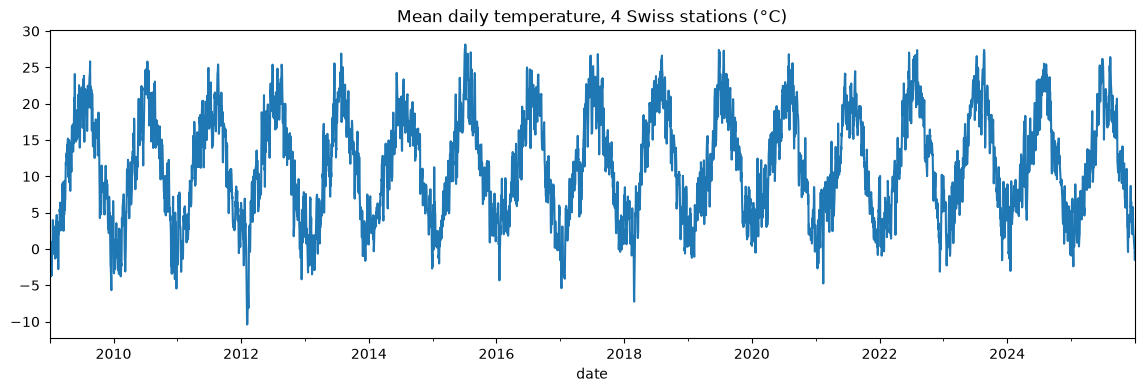

In [8]:
temps["temp_ch"] = temps[["SMA", "BER", "GVE", "LUG"]].mean(axis=1)   # mean across the 4 columns

temps["temp_ch"].plot(figsize=(14, 4), title="Mean daily temperature, 4 Swiss stations (°C)")

In [9]:
temps.to_csv("../data/processed/temperature_daily.csv", index_label="date")

## Lesson 9: Public holidays (and a trap)

In [10]:
import holidays

full_range = pd.date_range("2009-01-01", "2025-12-31", freq="D")
cantons = [c for c in holidays.Switzerland.subdivisions if len(c) == 2]   # the 26 cantons
print(len(cantons), "cantons")

holiday_count = pd.Series(0, index=full_range)
for c in cantons:
    days = holidays.Switzerland(years=range(2009, 2026), subdiv=c)
    holiday_count += full_range.isin(pd.to_datetime(list(days.keys())))   # +1 where it's a holiday

holiday_count["2024-12-20":"2024-12-31"]

26 cantons


2024-12-20     0
2024-12-21     0
2024-12-22     0
2024-12-23     0
2024-12-24     0
2024-12-25    26
2024-12-26    16
2024-12-27     0
2024-12-28     0
2024-12-29     0
2024-12-30     0
2024-12-31     1
Freq: D, dtype: int64

In [11]:
holidays_df = pd.DataFrame({
    "holiday_share": holiday_count / len(cantons),   # 0 = nowhere, 1 = whole country
})
holidays_df["is_holiday"] = holidays_df["holiday_share"] >= 0.5   # holiday in at least half the cantons

print("holidays per year (approx.):", holidays_df["is_holiday"].sum() / 17)
holidays_df[holidays_df["is_holiday"]].loc["2024"]

holidays per year (approx.): 9.0


,holiday_share,is_holiday
2024-01-01,1.000000,True
2024-03-29,0.884615,True
2024-04-01,0.730769,True
2024-05-09,1.000000,True
2024-05-20,0.730769,True
2024-08-01,1.000000,True
2024-11-01,0.500000,True
2024-12-25,1.000000,True
2024-12-26,0.615385,True


## Lesson 10: Build the final dataset

In [12]:
cons = pd.read_csv("../data/processed/swissgrid_daily.csv", index_col="date", parse_dates=True)

dataset = (
    cons[["consumption_gwh"]]
    .join(temps["temp_ch"])      # join = match rows by date (the index)
    .join(holidays_df)
)
dataset["weekday"] = dataset.index.day_of_week   # 0 = Monday ... 6 = Sunday
dataset["month"] = dataset.index.month

print(dataset.shape)
print(dataset.isna().sum())
dataset.head()

(6209, 6)
consumption_gwh    0
temp_ch            0
holiday_share      0
is_holiday         0
weekday            0
month              0
dtype: int64


,consumption_gwh,temp_ch,holiday_share,is_holiday,weekday,month
date,,,,,,
2009-01-01,144.814633,0.000,1.000000,True,3,1
2009-01-02,154.269911,-0.775,0.230769,False,4,1
2009-01-03,160.924955,-2.800,0.000000,False,5,1
2009-01-04,154.638229,-3.750,0.000000,False,6,1
2009-01-05,188.023687,-3.825,0.000000,False,0,1


correlation: -0.745


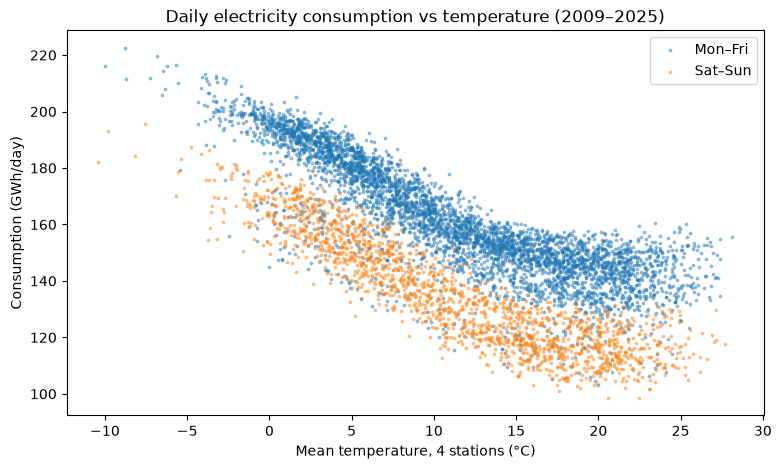

In [13]:
work = dataset["weekday"] < 5          # Monday–Friday

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(dataset.loc[work, "temp_ch"], dataset.loc[work, "consumption_gwh"],
           s=3, alpha=0.4, label="Mon–Fri")
ax.scatter(dataset.loc[~work, "temp_ch"], dataset.loc[~work, "consumption_gwh"],
           s=3, alpha=0.4, label="Sat–Sun")
ax.set_xlabel("Mean temperature, 4 stations (°C)")
ax.set_ylabel("Consumption (GWh/day)")
ax.set_title("Daily electricity consumption vs temperature (2009–2025)")
ax.legend()
fig.savefig("../figures/consumption_vs_temperature.png", dpi=150, bbox_inches="tight")

print("correlation:", dataset["consumption_gwh"].corr(dataset["temp_ch"]).round(3))

In [14]:
dataset.to_csv("../data/processed/dataset_daily.csv", index_label="date")